In [1]:
# =====================================
# CNN1D + MAMBA FULLY SEGMENT EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_fully_segment_mamba_classifier import RunFullySegmentMamba
from src.run.preprocess.config import _project_path


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.9967 | train_accuracy=0.4333 | train_f1=0.4848 | train_auc=0.4160 | train_precision=0.4324 | train_recall=0.5517 | train_specificity=0.3226 | val_loss=0.5161 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8393 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.7125 | train_accuracy=0.5167 | train_f1=0.2927 | train_auc=0.6696 | train_precision=0.5000 | train_recall=0.2069 | train_specificity=0.8065 | val_loss=0.5416 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8571 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6086 | train_accuracy=0.7000 | train_f1=0.6786 | train_auc=0.7375 | train_precision=0.7037 | train_recall=0.6552 | train_specificity=0.7419 | val_loss=0.5399 | val_accuracy=0.7333 | val_f1=0.7500 | val_auc=0.8036 | va

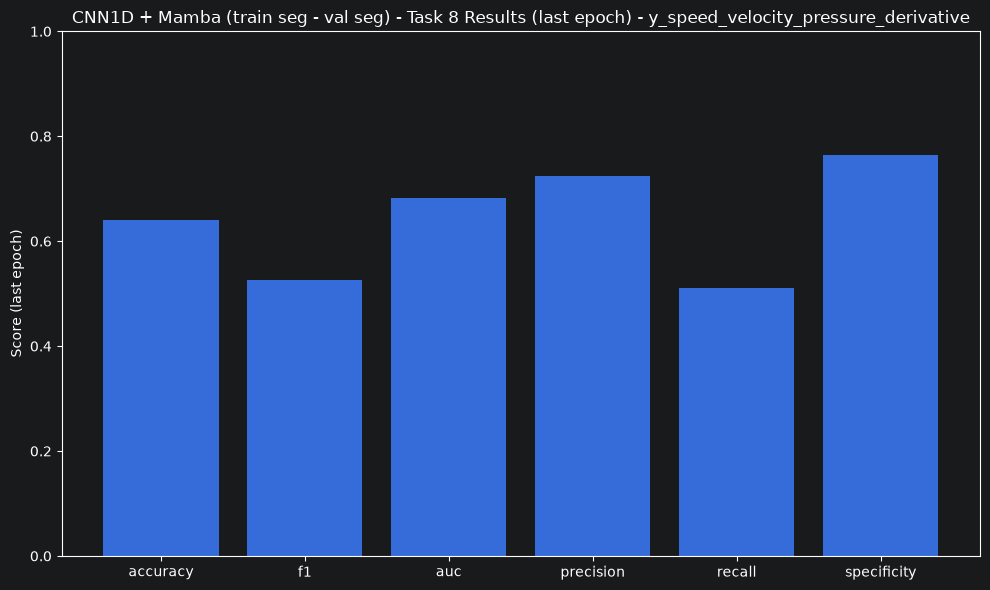

In [2]:
# =====================================
# RUN EXPERIMENT
# task 8 -> y_speed_velocity_pressure_derivative
# =====================================

runner = RunFullySegmentMamba(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[8],
    feature_names=("y",),
    engineered_features=("speed", "velocity", "pressure_derivative",),
    window_size=256,
    batch_size=16,
    epochs=50,
    learning_rate=1e-3,
    regularization=1e-3,
    n_splits=5,
    normalize=True,
    seed=42,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    output_dir=_project_path("experiments/ant/cnn1D + mamba/raw_segment(train_seg - val_seg)/task_8/y_speed_velocity_pressure_derivative"),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": float("inf"),
        "min_delta": 0,
        "results_writer": "csv",
        "save_metrics": True,
    },
)

summary = runner.run()

# =====================================
# RESULTS (last epoch)
# =====================================

averages = summary["averages"]

print("\n=== FINAL RESULTS (last epoch) ===")

print(f"Accuracy:    {averages['last_val_accuracy']:.4f}")
print(f"F1 Score:    {averages['last_val_f1']:.4f}")
print(f"AUC:         {averages['last_val_auc']:.4f}")
print(f"Precision:   {averages['last_val_precision']:.4f}")
print(f"Recall:      {averages['last_val_recall']:.4f}")
print(f"Specificity: {averages['last_val_specificity']:.4f}")

# =====================================
# BUILD DATAFRAME
# =====================================

df = pd.DataFrame([{
    "accuracy": averages["last_val_accuracy"],
    "f1": averages["last_val_f1"],
    "auc": averages["last_val_auc"],
    "precision": averages["last_val_precision"],
    "recall": averages["last_val_recall"],
    "specificity": averages["last_val_specificity"],
}])

# =====================================
# PLOT
# =====================================

metrics = [
    "accuracy",
    "f1",
    "auc",
    "precision",
    "recall",
    "specificity",
]

values = [
    averages[f"last_val_{m}"]
    for m in metrics
]

plt.figure(figsize=(10, 6))

plt.bar(
    metrics,
    values,
)

plt.ylim(0, 1)

plt.ylabel("Score (last epoch)")

plt.title(
    "CNN1D + Mamba (train seg - val seg) - Task 8 Results (last epoch) - y_speed_velocity_pressure_derivative"
)

plt.tight_layout()

plt.show()